In [1]:
%reload_ext autoreload
%autoreload 2

In [2]:
import os

os.environ['CUDA_VISIBLE_DEVICES'] = '1'
os.environ['XLA_PYTHON_CLIENT_MEM_FRACTION'] = '1'

In [3]:
import jax.numpy as jnp
import numpy as np
from scipy.stats import qmc
import matplotlib.pyplot as plt
from corner import corner, overplot_lines, overplot_points

from utils.linear_model import get_ODR, get_OLS, xy2logxy

In [4]:
k = 1.3
b = 0.1
sig = 0.2
N = 10000

x = np.random.uniform(0.1, 10, size=N)

y = 10 ** (k * np.log10(x) + b + np.random.normal(0, sig, size=N))

x_err = np.random.uniform(0.1, 0.5, size=N)
x_obs = np.random.normal(x, x_err)

y_err = np.random.uniform(0.1, 0.5, size=N)
y_obs = np.random.normal(y, y_err)

x_err = jnp.asarray(x_err)
x_obs = jnp.asarray(x_obs)
y_err = jnp.asarray(y_err)
y_obs = jnp.asarray(y_obs)

In [5]:
logx_obs, logy_obs, logx_err, logy_err = xy2logxy(x_obs, y_obs, x_err, y_err)

/work/jingtao/workspace/myrepos/raddest/example/utils/linear_model.py:24: RuntimeWarning: invalid value encountered in log10
  logx = np.log10(x)
/work/jingtao/workspace/myrepos/raddest/example/utils/linear_model.py:25: RuntimeWarning: invalid value encountered in log10
  logy = np.log10(y)


In [6]:
res_ODR = get_ODR(logx_obs, logy_obs)
res_OLS = get_OLS(logx_obs, logy_obs)

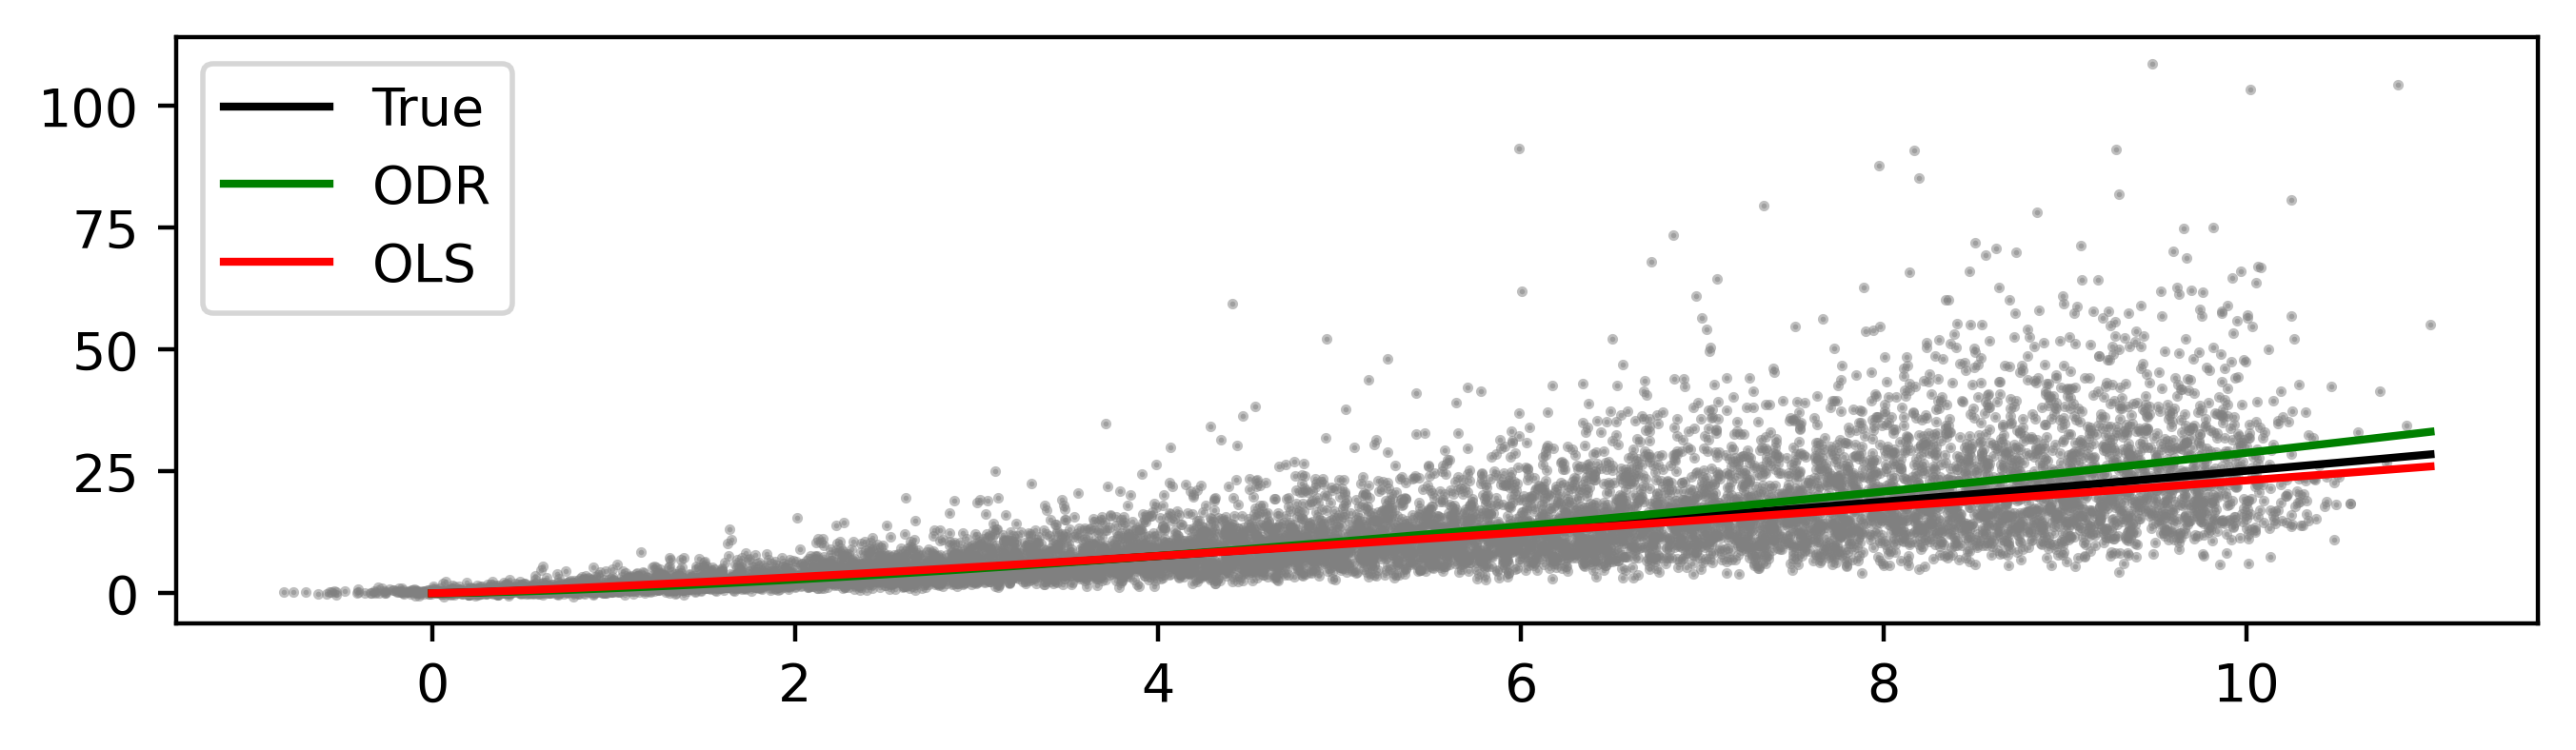

In [7]:
plt.figure(figsize=(8, 2), dpi=400)

plt.scatter(x_obs, y_obs, s=1, color='gray', alpha=0.5)
xx = np.linspace(max(1e-10, x_obs.min()), x_obs.max(), 100)
yy = 10 ** (k * np.log10(xx) + b)
yy_ODR = 10 ** res_ODR['func_xy'](np.log10(xx))
yy_OLS = 10 ** res_OLS['func'](np.log10(xx))

plt.plot(xx, yy, color='black', label='True')
plt.plot(xx, yy_ODR, color='green', label='ODR')
plt.plot(xx, yy_OLS, color='red', label='OLS')

plt.legend()

### Fit p(x, x_err) and p(y, y_err)

In [ ]:
from raddest.api.fitter import FlowVI, LogLinearML, LogLinearKS
from raddest.transfer import NegLogPlus

In [9]:
xflow = FlowVI(x_min=0,
               x_max=x_obs.max(),
               x_err_min=0,
               x_err_max=x_err.max() * 1.2,
               transfer=NegLogPlus())

xflow.fit(x_obs, x_err, verbose=True)

100%|██████████| 100/100 [00:08<00:00, 11.91it/s]


step 0: loss 0.8977075815200806
step 10: loss 0.870071291923523
step 20: loss 0.8642019033432007
step 30: loss 0.8556700944900513
step 40: loss 0.8537486791610718
step 50: loss 0.8524858951568604
step 60: loss 0.851676344871521


In [10]:
xflow.ks_test(x_obs, x_err, 10000)

(0.015600002370774746, 0.4066544446799522)

In [11]:
yflow = FlowVI(x_min=0,
               x_max=y_obs.max(),
               x_err_min=0,
               x_err_max=y_err.max() * 1.2,
               transfer=NegLogPlus())

yflow.fit(y_obs, y_err, verbose=True)

100%|██████████| 100/100 [00:08<00:00, 12.49it/s]


step 0: loss 2.0782792568206787
step 10: loss 2.0340936183929443
step 20: loss 2.0272133350372314
step 30: loss 2.0230865478515625
step 40: loss 2.021456480026245
step 50: loss 2.0205438137054443
step 60: loss 2.021352767944336


In [12]:
yflow.ks_test(y_obs, y_err, 10000)

(0.01434995885938406, 0.5140130719728206)

### ML Based Method

In [ ]:
logLinear_ML = LogLinearML(xflow, yflow)

In [ ]:
logLinear_ML.log_likelihood(
    x_obs, x_err, y_obs, y_err,
    jnp.array([[1.3, 0.1, 0.2], [1.2, 0.2, 0.1],
               [1.2, 0.1, -0.1]]))  # scale = -0.1 is regarded as 0.1

Array([-20486.605, -26788.965, -28625.037], dtype=float32)

In [ ]:
logLinear_ML.log_posterior(
    x_obs, x_err, y_obs, y_err,
    jnp.array([[1.3, 0.1, 0.2], [1.2, 0.2, 0.1], [1.2, 0.1, -0.1]]))

Array([-20486.605, -26788.965,       -inf], dtype=float32)

In [ ]:
params_ml, params_std, cov = logLinear_ML.fit(
    x_obs,
    x_err,
    y_obs,
    y_err,
    [1., 0., 0.1],
    kde_batch_size=None,  # set it to 100000 or less if OOM
    verbose=True)  # loss is log-likelihood/n_samples

0 1.0166242 0.021614373 0.17661831 -3.152353
1000 1.2507764 0.13205773 0.2036597 -2.050282
2000 1.2829233 0.10929295 0.20330234 -2.04855
3000 1.2927015 0.1023581 0.20326105 -2.0483897
4000 1.295708 0.10022485 0.2032545 -2.0483747
5000 1.2966322 0.09956844 0.20325315 -2.0483735
converged, so stop with 5000 iterations


In [17]:
print('ML fitted:', *params_ml)
print('Truth:', k, b, sig)

ML fitted: 1.2966322 0.09956844 0.20325315
Truth: 1.3 0.1 0.2


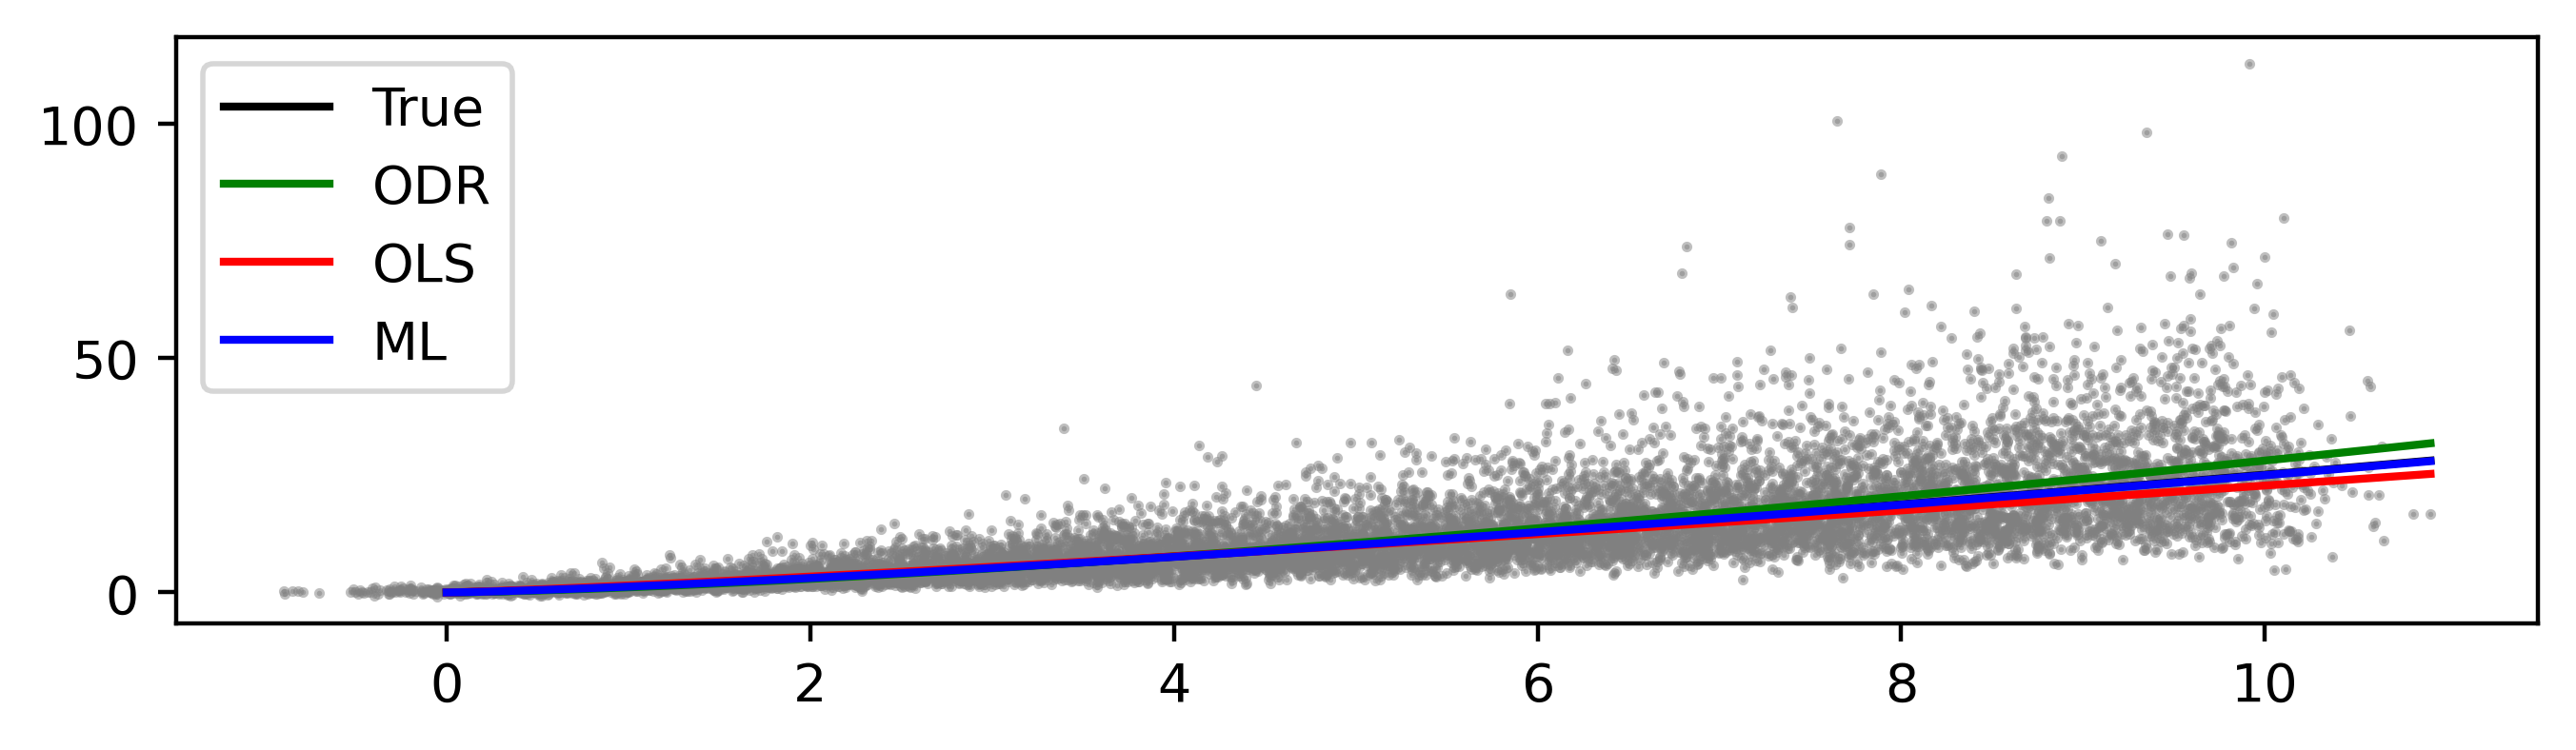

In [25]:
plt.figure(figsize=(8, 2), dpi=400)

plt.scatter(x_obs, y_obs, s=1, color='gray', alpha=0.5)
xx = np.linspace(max(1e-10, x_obs.min()), x_obs.max(), 100)
yy = 10 ** (k * np.log10(xx) + b)
yy_ODR = 10 ** res_ODR['func_xy'](np.log10(xx))
yy_OLS = 10 ** res_OLS['func'](np.log10(xx))
yy_ML = 10 ** (params_ml[0] * np.log10(xx) + params_ml[1])

plt.plot(xx, yy, color='black', label='True')
plt.plot(xx, yy_ODR, color='green', label='ODR')
plt.plot(xx, yy_OLS, color='red', label='OLS')
plt.plot(xx, yy_ML, color='blue', label='ML')

plt.legend()

In [ ]:
sampler = qmc.Sobol(d=3, scramble=True)
l_bounds = [
    max(params_ml[0] - 0.02, -2),
    max(params_ml[1] - 0.02, -2),
    max(params_ml[2] - 0.02, 0.1)
]
u_bounds = [
    min(params_ml[0] + 0.02, 2),
    min(params_ml[1] + 0.02, 2),
    min(params_ml[2] + 0.02, 0.5)
]
params_grid = qmc.scale(sampler.random_base2(m=15), l_bounds, u_bounds)

log_posterior = logLinear_ML.log_posterior(x_obs, x_err, y_obs, y_err,
                                               params_grid)

weight = jnp.exp(log_posterior - log_posterior.max())

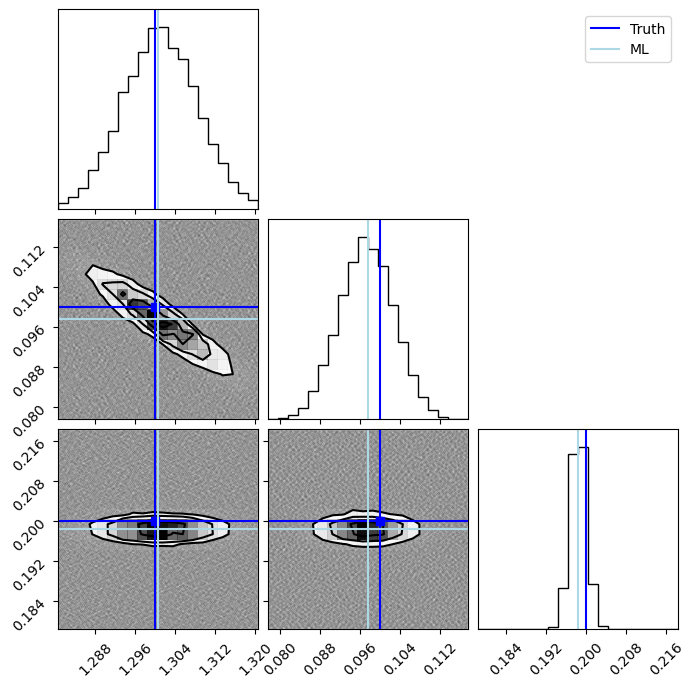

In [27]:
cor_fig = corner(np.asarray(params_grid),
                 weights=weight,
                 bins=20,
                 truths=[k, b, sig],
                 truth_color='blue')
overplot_lines(cor_fig, params_ml, color='lightblue')
overplot_lines(cor_fig, [res_ODR['k'][0], res_ODR['b'][0], None],
               color='green')
overplot_lines(cor_fig, [res_OLS['k'][1], res_OLS['b'][1], None], color='red')

# get axes from fig
ax = cor_fig.axes[2]
ax.plot([], [], color='blue', label='Truth')
ax.plot([], [], color='lightblue', label='ML')
ax.legend(loc='upper right')

In [ ]:
sampler = qmc.Sobol(d=3, scramble=True)
l_bounds = [1.15, 0, max(params_ml[2] - 0.02, 0.1)]
u_bounds = [1.45, 0.2, min(params_ml[2] + 0.02, 0.5)]
params_grid = qmc.scale(sampler.random_base2(m=15), l_bounds, u_bounds)

log_posterior = logLinear_ML.log_posterior(x_obs, x_err, y_obs,
                                                     y_err, params_grid)

weight = jnp.exp(log_posterior - log_posterior.max())

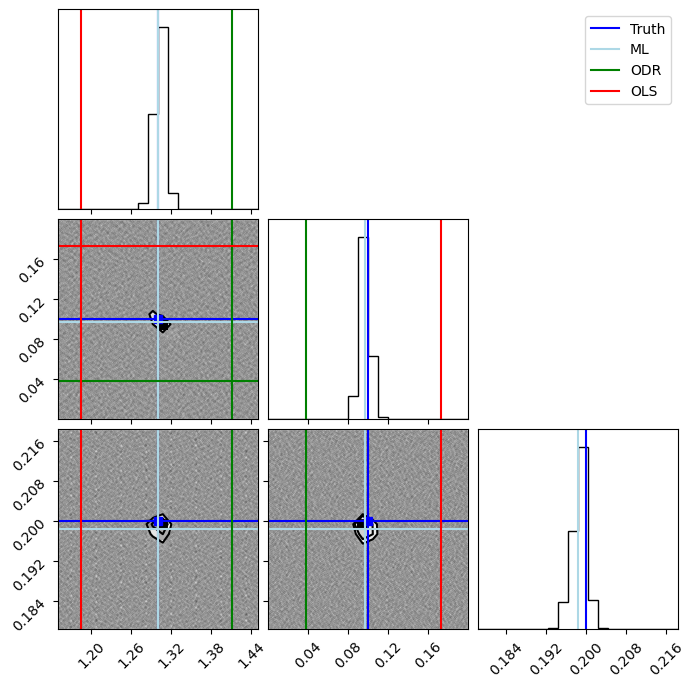

In [29]:
cor_fig = corner(np.asarray(params_grid),
                 weights=weight,
                 bins=20,
                 truths=[k, b, sig],
                 truth_color='blue')
overplot_lines(cor_fig, params_ml, color='lightblue')
overplot_lines(cor_fig, [res_ODR['k'][0], res_ODR['b'][0], None],
               color='green')
overplot_lines(cor_fig, [res_OLS['k'][0], res_OLS['b'][0], None], color='red')

# get axes from fig
ax = cor_fig.axes[2]
ax.plot([], [], color='blue', label='Truth')
ax.plot([], [], color='lightblue', label='ML')
ax.plot([], [], color='green', label='ODR')
ax.plot([], [], color='red', label='OLS')
ax.legend(loc='upper right')

In [ ]:
x_obs_gen, y_obs_gen, x_err_gen, y_err_gen, x_gen, y_gen = logLinear_ML.sample(
    params_ml)

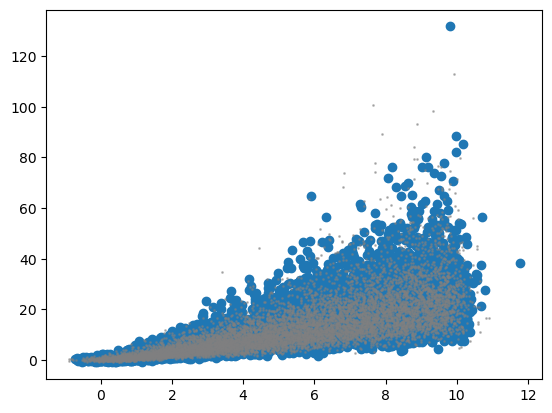

In [31]:
plt.scatter(x_obs_gen, y_obs_gen)
plt.scatter(x_obs, y_obs, s=1, color='gray', alpha=0.5)

In [ ]:
logLinear_ML.ks_test(params_ml, x_obs, y_obs)

(0.015449999831616879, 0.33682866912497034)

In [ ]:
D_lst, p_lst = logLinear_ML.ks_test(params_ml, x_obs, y_obs, K=10)

In [35]:
10**np.mean(np.log10(p_lst))

0.31481594394769435

### KS Based Method

In [ ]:
logLinear_KS = LogLinearKS(xflow, yflow)

In [ ]:
params_mean, params_std, res_arr = logLinear_KS.fit(
    x_obs,
    y_obs,
    params_list=[
        np.linspace(0.5, 1.5, 7),
        np.linspace(-0.1, 0.3, 7),
        np.linspace(0.1, 0.3, 5)
    ],
    verbose=True)
print(params_mean, params_std)

/home/jingtao/software/anaconda3/envs/rarden/lib/python3.9/site-packages/joblib/externals/loky/backend/fork_exec.py:38: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  pid = os.fork()


----
k: 1.227 +/- 0.149
b: 0.150 +/- 0.109
sig: 0.206 +/- 0.047
----
k: 1.271 +/- 0.109
b: 0.117 +/- 0.084
sig: 0.204 +/- 0.038
----
k: 1.267 +/- 0.089
b: 0.121 +/- 0.071
sig: 0.203 +/- 0.038
----
k: 1.262 +/- 0.096
b: 0.126 +/- 0.076
sig: 0.205 +/- 0.035
----
k: 1.258 +/- 0.097
b: 0.127 +/- 0.077
sig: 0.202 +/- 0.037
----
k: 1.283 +/- 0.100
b: 0.109 +/- 0.077
sig: 0.204 +/- 0.038
----
k: 1.280 +/- 0.088
b: 0.112 +/- 0.072
sig: 0.200 +/- 0.037
----
k: 1.265 +/- 0.096
b: 0.124 +/- 0.074
sig: 0.213 +/- 0.038
----
k: 1.264 +/- 0.094
b: 0.123 +/- 0.074
sig: 0.207 +/- 0.040
----
k: 1.261 +/- 0.101
b: 0.125 +/- 0.080
sig: 0.208 +/- 0.038
----
k: 1.246 +/- 0.093
b: 0.137 +/- 0.071
sig: 0.206 +/- 0.037
max iteration reached
[1.26593079 0.12183645 0.20519578] [0.08941198 0.06987475 0.03694608]


In [ ]:
regressor_logLinear_KS_quantile = LogLinearKS(xflow, yflow, gen_new_grid='quantile')

In [23]:
params_mean, params_std, res_arr = regressor_logLinear_KS_quantile.fit(
    x_obs,
    y_obs,
    params_list=[
        np.linspace(0.5, 1.5, 7),
        np.linspace(-0.1, 0.3, 7),
        np.linspace(0.1, 0.3, 5)
    ],
    verbose=True)
print(params_mean, params_std)

----
k: 1.267 +/- 0.100
b: 0.119 +/- 0.081
sig: 0.209 +/- 0.040
----
k: 1.276 +/- 0.093
b: 0.111 +/- 0.074
sig: 0.201 +/- 0.038
----
k: 1.269 +/- 0.094
b: 0.117 +/- 0.074
sig: 0.205 +/- 0.036
----
k: 1.278 +/- 0.109
b: 0.112 +/- 0.085
sig: 0.208 +/- 0.044
----
k: 1.287 +/- 0.094
b: 0.107 +/- 0.075
sig: 0.203 +/- 0.040
----
k: 1.287 +/- 0.106
b: 0.105 +/- 0.083
sig: 0.210 +/- 0.041
----
k: 1.273 +/- 0.096
b: 0.114 +/- 0.075
sig: 0.202 +/- 0.037
----
k: 1.259 +/- 0.089
b: 0.125 +/- 0.071
sig: 0.211 +/- 0.037
----
k: 1.267 +/- 0.084
b: 0.121 +/- 0.069
sig: 0.201 +/- 0.037
----
k: 1.258 +/- 0.094
b: 0.126 +/- 0.074
sig: 0.206 +/- 0.036
----
k: 1.264 +/- 0.098
b: 0.125 +/- 0.077
sig: 0.203 +/- 0.040
max iteration reached
[1.26918283 0.11955436 0.20395747] [0.09104378 0.07213032 0.03878941]
